# Tasks 3 and 4: Voice Recordings, Audio Features and the Voiceprint Verification Model

**Formative 2: Multimodal Data Preprocessing** · Audio lead: Agnes Mbabazi, GitHub @agmbabazi

This notebook walks through the audio half of the authentication system, using the same code the app uses:

| Step | Code | Output |
|---|---|---|
| Convert, trim, normalise, check every recording | `scripts/audio_pipeline.py` | `audio/processed/*.wav`, collection report |
| Waveforms and spectrograms | this notebook | `figures/audio_01_*.png`, `figures/audio_02_*.png` |
| Augment every recording 5 ways | `scripts/audio_pipeline.py` | `audio/augmented/*.wav` |
| Extract MFCCs, roll-off, centroid, zero-crossing rate, energy | `scripts/audio_pipeline.py` | `features/audio_features.csv` |
| Train and evaluate the speaker + phrase models, tune the threshold | `scripts/voice_model.py` | `models/voice_model.joblib` |
| `verify_voice(audio_path)` for the command-line app | `scripts/voice_model.py` | `"<member>"` or `"unauthorized"` |

Run from the repository root's `notebooks/` folder; it needs `ffmpeg` installed and `pip install -r requirements.txt`.

In [1]:
import sys
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)   # librosa's audioread notices
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import audio_pipeline as ap
import voice_model as vm

FIGURES = ROOT / "figures"
# One fixed colour per member (validated colour-blind-safe categorical palette), used in every plot.
COLORS = {"agnes": "#2a78d6", "aime": "#eb6834", "naillah": "#1baf7a", "sheja": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#999",
                     "axes.labelcolor": "#333", "xtick.color": "#555", "ytick.color": "#555",
                     "axes.titlesize": 10, "font.size": 9, "figure.dpi": 100})

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=130, bbox_inches="tight")

## 1. Collection check

Every member recorded two phrases on their phone: **"Yes, approve"** and **"Confirm transaction"**, and several members recorded extra takes.
Files follow one naming format, `<member>_<phrase>[_<take>].m4a`, in `audio/raw/` (originals, never changed).

Before anything else, each recording is:

1. **converted** with ffmpeg to 16 kHz mono WAV (`audio/processed/`), so every clip has the same format whatever phone recorded it;
2. **trimmed**: silence more than 30 dB below the loudest point is cut from the start and end. People paused for very different lengths before speaking (Aime's first "yes approve" is 4.0 s long but only 1.25 s of speech). Untrimmed, a model could learn the pause instead of the voice. 10 dB cut into the words and 60 dB kept the pauses;
3. **checked**: a valid name, 0.5 to 5 s of speech, no clipping (peak below 0.99), and **not an exact copy** of another file. Copies are detected by a fingerprint (MD5 hash) of the audio, so renaming a file does not hide it. A copy adds no information, and it would put the same recording in both the training and the test data. In a test, renamed copies pushed accuracy to a fake 100%.

In [2]:
converted = ap.convert_m4a()
print("Newly converted to WAV:", ", ".join(converted) or "none (all up to date)")
report = ap.collection_report()
display(report)
print("Recordings per member and phrase:")
display(report[report["ok"]].groupby(["member", "phrase"]).size().unstack())
print("Missing phrases:", ap.missing_phrases(report) or "none")

Newly converted to WAV: none (all up to date)


,file,member,phrase,valid_name,duplicate_of,duration_s,peak,ok
0,agnes_confirmtransaction.wav,agnes,confirmtransaction,True,None,2.11,0.235,True
1,agnes_confirmtransaction_1.wav,agnes,confirmtransaction,True,None,2.28,0.145,True
2,agnes_confirmtransaction_2.wav,agnes,confirmtransaction,True,None,2.14,0.149,True
3,agnes_yesapprove.wav,agnes,yesapprove,True,None,2.08,0.306,True
4,agnes_yesapprove_1.wav,agnes,yesapprove,True,None,1.44,0.136,True
5,agnes_yesapprove_2.wav,agnes,yesapprove,True,None,2.27,0.093,True
6,aime_confirmtransaction.wav,aime,confirmtransaction,True,None,2.05,0.298,True
7,aime_yesapprove.wav,aime,yesapprove,True,None,1.25,0.425,True
8,naillah_confirmtransaction.wav,naillah,confirmtransaction,True,None,2.56,0.163,True
9,naillah_confirmtransaction_1.wav,naillah,confirmtransaction,True,None,2.11,0.094,True


Recordings per member and phrase:


phrase,confirmtransaction,yesapprove
member,,
agnes,3,3
aime,1,1
naillah,3,3
sheja,1,1


Missing phrases: none


## 2. Waveforms and spectrograms

For each member's first take of each phrase (after trimming and volume normalisation):

* the **waveform** shows the sound pressure over time. Bursts are syllables, flat stretches are pauses;
* the **mel spectrogram** shows which frequencies carry energy over time (darker means louder). The frequency axis is on the *mel* scale, which, like human hearing, gives more room to low frequencies, where voices differ most.

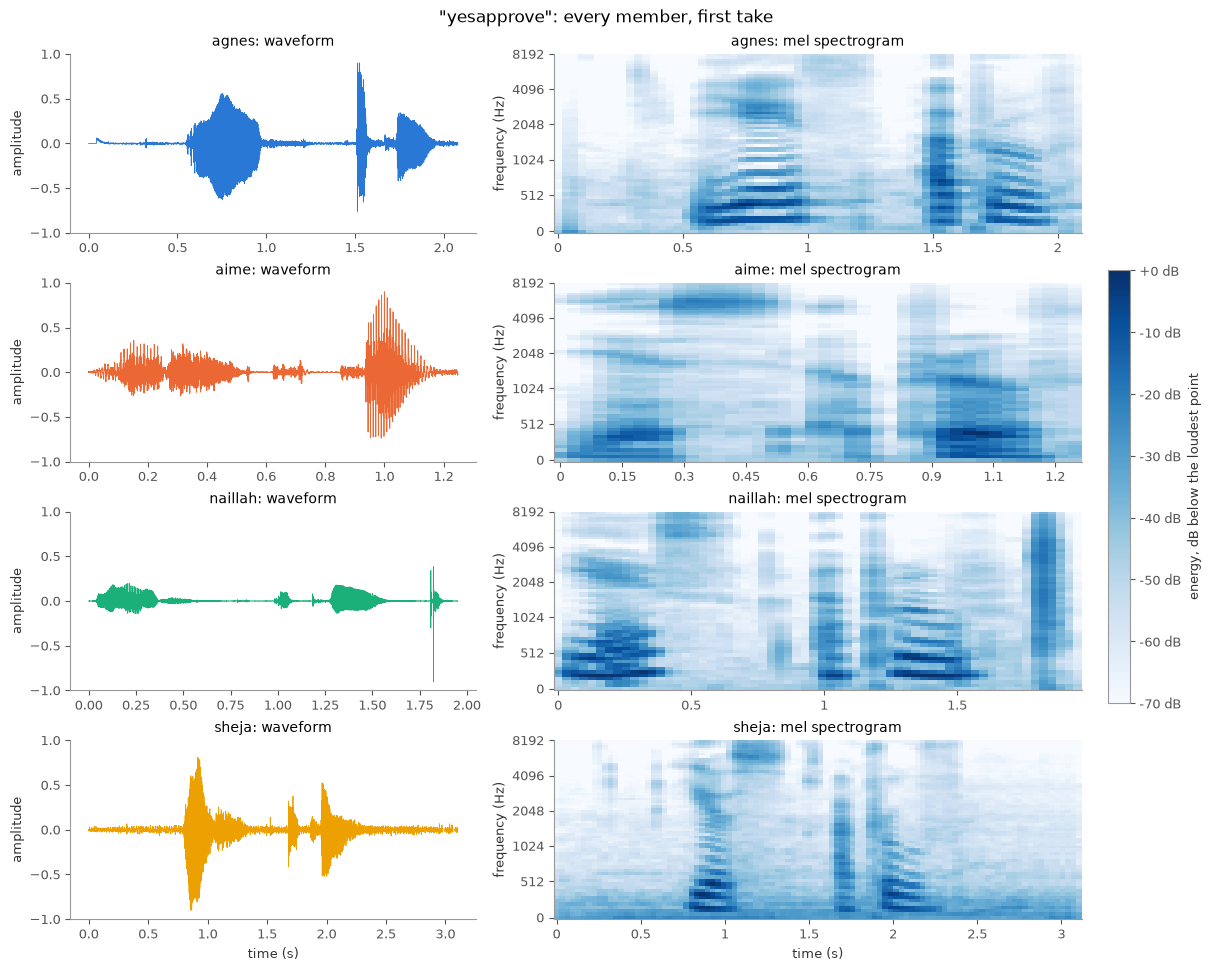

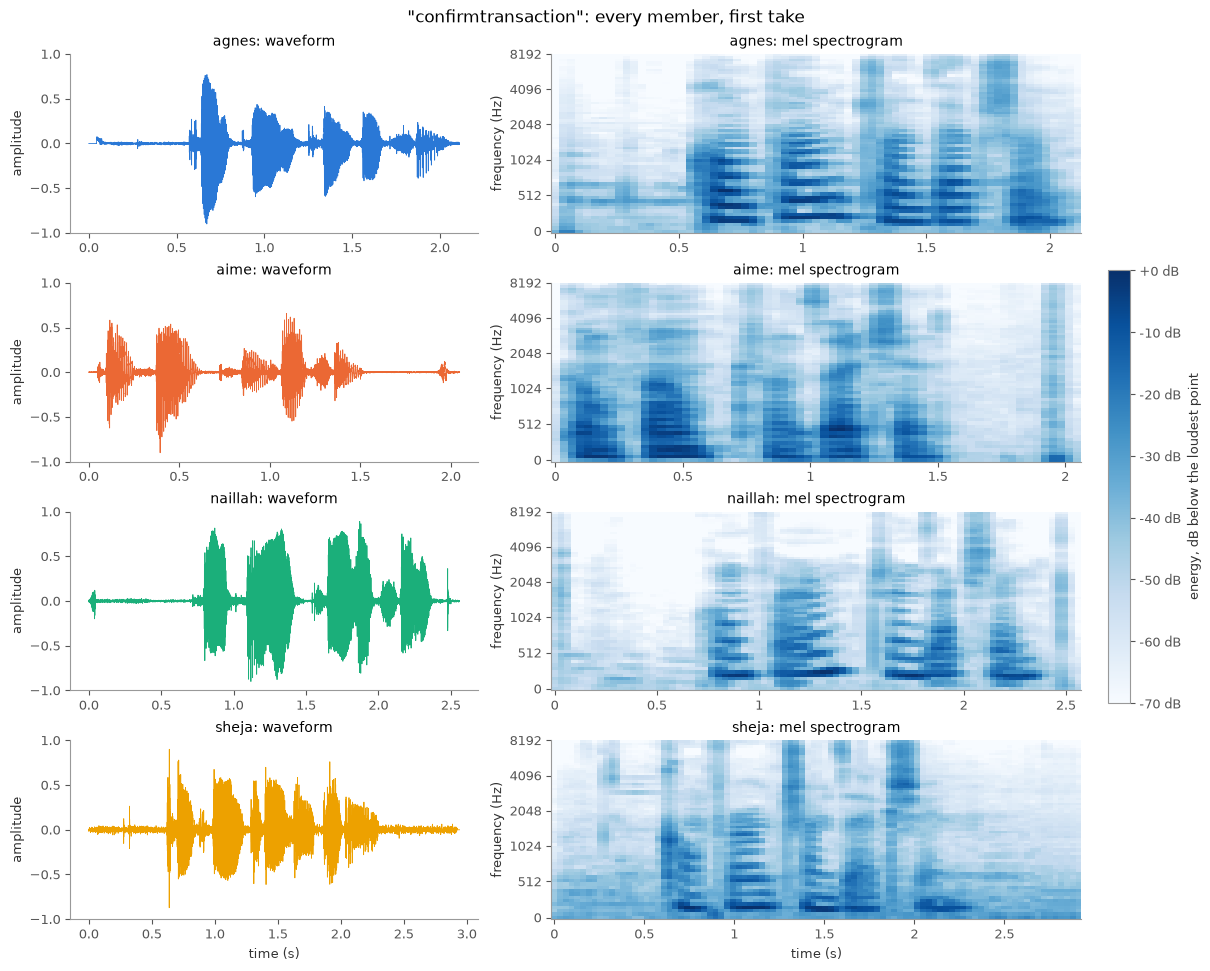

In [3]:
members = sorted(COLORS)

def phrase_figure(phrase, take=""):
    fig, axes = plt.subplots(len(members), 2, figsize=(12, 2.4 * len(members)), constrained_layout=True,
                             gridspec_kw={"width_ratios": [1, 1.3]})
    for row, member in enumerate(members):
        y = ap.load_clip(ap.PROCESSED / f"{member}_{phrase}{take}.wav")
        t = np.arange(len(y)) / ap.SAMPLE_RATE
        ax = axes[row, 0]
        ax.plot(t, y, color=COLORS[member], lw=0.6)
        ax.set(ylim=(-1, 1), ylabel="amplitude", title=f"{member}: waveform")
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=ap.SAMPLE_RATE, n_mels=64), ref=np.max)
        img = librosa.display.specshow(S, sr=ap.SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[row, 1],
                                       cmap="Blues", vmin=-70, vmax=0)
        axes[row, 1].set(ylabel="frequency (Hz)", title=f"{member}: mel spectrogram")
        axes[row, 0].set_xlabel("time (s)" if row == len(members) - 1 else "")
        axes[row, 1].set_xlabel("time (s)" if row == len(members) - 1 else "")
    fig.colorbar(img, ax=axes[:, 1], format="%+.0f dB", shrink=0.5, label="energy, dB below the loudest point")
    fig.suptitle(f'"{phrase}": every member, first take', fontsize=12)
    return fig

for i, phrase in enumerate(ap.PHRASES, start=1):
    fig = phrase_figure(phrase)
    save(fig, f"audio_0{i}_{phrase}_waveforms_spectrograms.png")
    plt.show()

### What the plots show

* **The two phrases have different shapes, for everyone.** "Yes, approve" has two or three bursts ("yes", "ap-", "-prove"), while "Confirm transaction" has four or five ("con-firm trans-ac-tion"). Because the *words* change the picture this much, a model fed whole-clip averages learned the phrase rather than the person. This is why features are measured in short windows (section 4).
* **Voiced sounds show horizontal stripes (harmonics).** These are multiples of the speaker's pitch. Their spacing and the bands where energy collects (formants) depend on the speaker's vocal tract. MFCCs summarise exactly this envelope.
* **Sheja's recordings carry a constant low-frequency haze** (below about 300 Hz) across the whole clip, even in pauses. That is background hum in the room. It is why her clips barely trimmed, and it is a risk: the model can partly recognise *Sheja's room* rather than *Sheja's voice*.
* **Naillah's first "yes, approve" ends with a click** at about 1.8 s: a sharp vertical line from the bottom to the top of the spectrogram, and the waveform's tallest spike. That is the phone being stopped, not speech. It explains her unusually high peak (0.865) in the collection check.
* **Aime's "yes, approve" has a high-frequency band around 4 kHz** at the start, the hiss of the "s" in "yes", with Aime's voiced energy sitting lower and later in the clip.
* After normalisation, every waveform reaches the same peak (0.9), so loudness differences between phones no longer reach the model.

In [4]:
# Listen to one clip per member (the notebook keeps the players)
for member in members:
    print(member)
    display(Audio(ap.load_clip(ap.PROCESSED / f"{member}_yesapprove.wav"), rate=ap.SAMPLE_RATE))

agnes


aime


naillah


sheja


## 3. Augmentations

Every recording gets 5 augmented versions, each standing for a way a real login recording can differ from the enrolled one.
Strengths were not guessed: each was measured by how far it moves a clip's average MFCCs, compared with the gap between two *different* members saying the same phrase.
An augmentation must stay well below that gap, or it turns one person into "someone else".

| Augmentation | Setting | Moves the voice by (avg) | Rejected alternatives |
|---|---|---|---|
| `pitch_up` / `pitch_down` | ±1 semitone | 11.7 | ±4 semitones moved it 34.2, past another member (gap ≥ 27.8) |
| `faster` / `slower` | 1.1× / 0.9× speed, same pitch | about 5 | (all speeds were safe: speed hardly changes MFCCs) |
| `noisy` | white noise at 40 dB SNR (voice 10,000× stronger) | 12.3 | 30 dB moved it 32.3, 10 dB moved it 79.4 |

Noise turned out to be the most damaging: MFCCs are sensitive to it, so a login from a noisy room is the most likely to fail.
The table below recomputes these distances on the current recordings.

/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


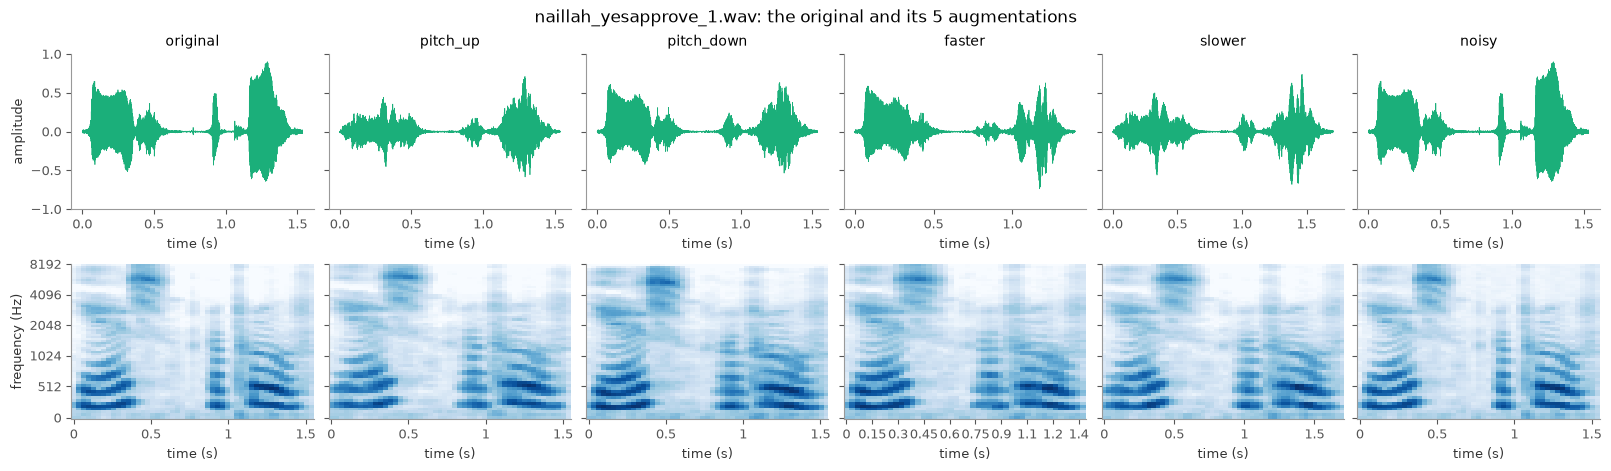

In [5]:
sample = ap.PROCESSED / "naillah_yesapprove_1.wav"
versions = ap.augment(ap.load_clip(sample))
fig, axes = plt.subplots(2, len(versions), figsize=(16, 4.6), constrained_layout=True, sharey="row")
for col, (name, y) in enumerate(versions.items()):
    axes[0, col].plot(np.arange(len(y)) / ap.SAMPLE_RATE, y, color=COLORS["naillah"], lw=0.5)
    axes[0, col].set(title=name, ylim=(-1, 1), xlabel="time (s)")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=ap.SAMPLE_RATE, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=ap.SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[1, col], cmap="Blues", vmin=-70, vmax=0)
    axes[1, col].set(ylabel="", xlabel="time (s)")
axes[0, 0].set_ylabel("amplitude"); axes[1, 0].set_ylabel("frequency (Hz)")
fig.suptitle(f"{sample.name}: the original and its 5 augmentations", fontsize=12)
save(fig, "audio_03_augmentations.png")
plt.show()

In [6]:
def voiceprint(y):  # average MFCC 1-13 of a clip
    return librosa.feature.mfcc(y=y, sr=ap.SAMPLE_RATE, n_mfcc=14)[1:].mean(axis=1)

clips = {p.name: ap.load_clip(p) for p in ap.unique_clips() if ap.unique_clips()[p] is None}
prints = {name: voiceprint(y) for name, y in clips.items()}
member_of = lambda name: ap.NAME_PATTERN.match(name).group(1)
phrase_of = lambda name: ap.NAME_PATTERN.match(name).group(2)
between = [np.linalg.norm(prints[a] - prints[b]) for a in prints for b in prints
           if a < b and member_of(a) != member_of(b) and phrase_of(a) == phrase_of(b)]
shift = {name: np.mean([np.linalg.norm(voiceprint(fn(y)) - prints[c]) for c, y in clips.items()])
         for name, fn in ap.AUGMENTATIONS.items()}
print(f"Distance between two different members (same phrase): smallest {min(between):.1f}, average {np.mean(between):.1f}")
display(pd.Series(shift, name="average shift of the voiceprint").round(1).to_frame())

/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


Distance between two different members (same phrase): smallest 19.8, average 39.7


,average shift of the voiceprint
pitch_up,12.500000
pitch_down,22.799999
faster,5.800000
slower,5.200000
noisy,11.700000


## 4. Feature extraction: `audio_features.csv`

librosa cuts each clip into short overlapping **frames** (128 ms, every 32 ms) and measures in each frame:

| Feature | Columns | What it captures |
|---|---|---|
| **MFCCs 1 to 13** | `mfcc_01` … `mfcc_13` | The shape of the spectrum's envelope, which is set by the speaker's throat, mouth and nose. The standard voiceprint feature. (MFCC 0 is overall loudness, already covered by RMS, so it is dropped.) |
| **Spectral roll-off** | `rolloff` | The frequency below which 85% of the energy sits: how "bright" or "dark" the voice is |
| **Spectral centroid** | `centroid` | The spectrum's centre of mass, another brightness measure |
| **Zero-crossing rate** | `zcr` | How often the waveform crosses zero: high for hissy sounds ("s", "f"), low for vowels |
| **RMS energy** | `rms` | Loudness of each frame. After normalisation this describes how loudness *changes* through the phrase, not phone distance |

The frames are then grouped into **0.5 s windows (every 0.25 s)**, and each window becomes one row: the **mean and standard deviation** of every feature, giving 34 numbers.
Why windows rather than one row per clip: with whole-clip averages the model scored 23 to 35%, the same as guessing (25%), because the averages mostly encoded *which words* were said.
Short windows give the model many small pieces of each voice. When a clip is classified, its windows' answers are averaged.

`source_clip` records which original recording a row came from, so the model can keep a recording and all its augmented copies on the same side of a train/test split.

In [7]:
features = ap.build_features()
ap.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
features.to_csv(ap.FEATURES_FILE, index=False)
print(f"Saved {ap.FEATURES_FILE.relative_to(ROOT)}: {features.shape[0]} rows x {features.shape[1]} columns, "
      f"{features.isna().sum().sum()} missing values")
display(features.head())
print("Window rows per member and augmentation:")
display(features.groupby(["member", "augmentation"]).size().unstack())

/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


Saved features/audio_features.csv: 688 rows x 39 columns, 0 missing values


,member,phrase,augmentation,source_clip,segment,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,...,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,centroid_mean,centroid_std,zcr_mean,zcr_std,rms_mean,rms_std
0,agnes,confirmtransaction,original,agnes_confirmtransaction.wav,0,114.329188,8.413377,22.104243,11.047094,9.906109,...,7.179597,2.939383,2784.179688,778.314186,1240.249078,211.367947,0.062408,0.022414,0.010889,0.005768
1,agnes,confirmtransaction,original,agnes_confirmtransaction.wav,1,129.093976,25.498923,14.762260,16.837711,-11.088720,...,6.958222,4.723981,2502.929688,1107.998276,1226.622001,270.700350,0.077209,0.017063,0.085389,0.109044
2,agnes,confirmtransaction,original,agnes_confirmtransaction.wav,2,135.081989,27.933693,-1.721079,15.678559,-20.456233,...,3.467440,5.577089,1925.292969,1145.697094,1135.163765,400.504588,0.089447,0.030249,0.148884,0.089435
3,agnes,confirmtransaction,original,agnes_confirmtransaction.wav,3,120.154908,29.996591,-5.538941,17.357299,-6.328544,...,0.513146,4.789247,2098.632812,1520.381739,1200.152465,629.357315,0.084808,0.046909,0.127664,0.062617
4,agnes,confirmtransaction,original,agnes_confirmtransaction.wav,4,122.336727,39.984170,0.969026,22.356133,-7.062382,...,0.707827,4.131627,2380.371094,1903.876594,1278.057814,787.677855,0.095978,0.066169,0.118872,0.049292


Window rows per member and augmentation:


augmentation,faster,noisy,original,pitch_down,pitch_up,slower
member,,,,,,
agnes,36,41,41,41,41,46
aime,9,11,11,11,11,12
naillah,37,42,42,42,42,46
sheja,19,21,21,21,21,23


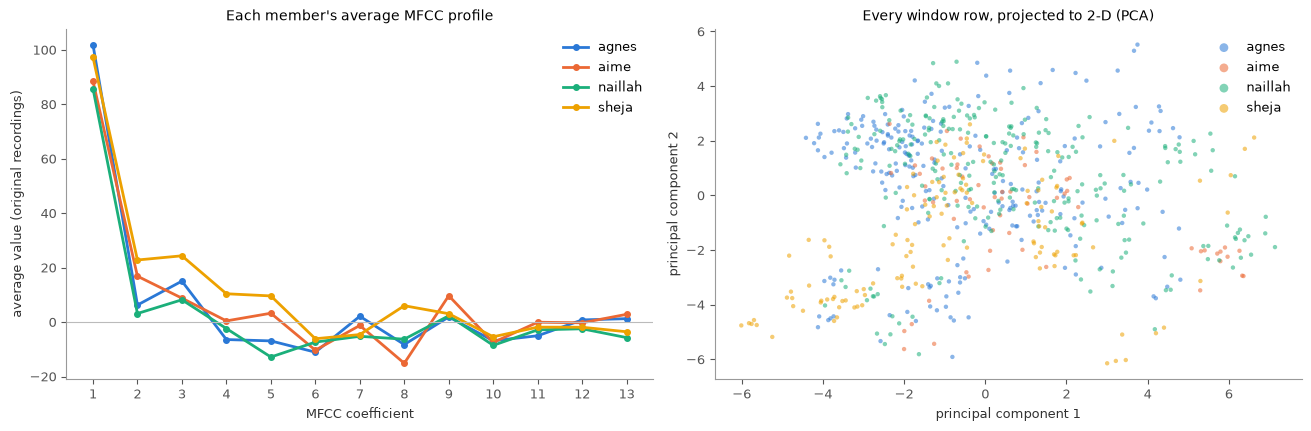

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
originals = features[features["augmentation"] == "original"]
mfcc_means = [c for c in ap.NUMERIC_COLUMNS if c.startswith("mfcc") and c.endswith("_mean")]
for member, rows in originals.groupby("member"):
    axes[0].plot(range(1, 14), rows[mfcc_means].mean(), marker="o", ms=4, lw=2, color=COLORS[member], label=member)
axes[0].axhline(0, color="#bbb", lw=0.8)
axes[0].set(xticks=range(1, 14), xlabel="MFCC coefficient", ylabel="average value (original recordings)",
            title="Each member's average MFCC profile")
axes[0].legend(frameon=False)

X = StandardScaler().fit_transform(features[ap.NUMERIC_COLUMNS])
points = PCA(n_components=2, random_state=0).fit_transform(X)
for member in members:
    m = (features["member"] == member).to_numpy()
    axes[1].scatter(points[m, 0], points[m, 1], s=10, alpha=0.55, color=COLORS[member], label=member, edgecolors="none")
axes[1].set(xlabel="principal component 1", ylabel="principal component 2",
            title="Every window row, projected to 2-D (PCA)")
axes[1].legend(frameon=False, markerscale=2)
save(fig, "audio_04_features.png")
plt.show()

**Reading these plots.** The MFCC profiles share one overall shape (a large first coefficient, then small values around zero: the shape of human speech), and members differ in the details spread across the coefficients: Sheja is higher on 2 to 5, Aime stands out at 8 and 9, and Agnes peaks at 3 and 7.
In the 2-D projection the members overlap heavily, with only part of Sheja's windows drifting apart (towards the bottom left), consistent with her room noise.
So no single direction separates the voices, and with the data we have, recognising a voice will be hard. The next section measures exactly how hard.

## 5. Voiceprint model

**Two Logistic Regression models** on the 34 window features (standardised first: MFCCs are in the hundreds, ZCR is below 1):

* **speaker model:** *who* is talking (agnes, aime, naillah, sheja). Classes are weighted so members with more recordings don't dominate;
* **phrase model:** *what* they said (yes approve or confirm transaction).

A clip's answer is the average of its windows' probabilities. Logistic Regression was chosen after comparing it with an RBF SVM and a Random Forest under the same evaluation. The SVM did no better and the Random Forest did worse, and Logistic Regression's probabilities give a meaningful log loss.

**Evaluation holds out whole recordings** (`StratifiedGroupKFold`, grouped by `source_clip`): a recording and its 5 augmented copies are always on the same side.
Testing on a pitch-shifted copy of a training clip would overstate accuracy. Every metric below is on recordings the model never trained on.

,held-out score
accuracy,0.677
f1_macro,0.588
log_loss,1.298


For reference, guessing among 4 members gives accuracy 0.25 and log loss 1.39


Phrase model accuracy on members it never heard: 0.625


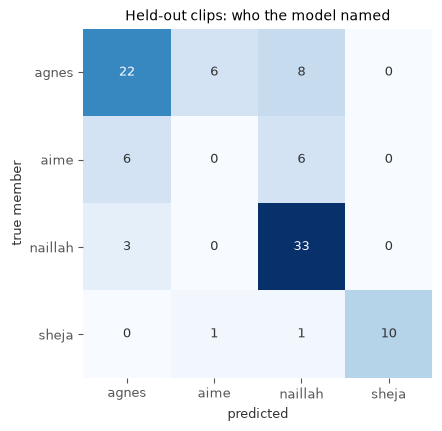

,recordings,clips,correct
member,,,
agnes,6,36,0.61
aime,2,12,0.00
naillah,6,36,0.92
sheja,2,12,0.83


In [9]:
held_out, classes = vm.evaluate(features)
scores = vm.metrics(held_out, classes)
display(pd.Series(scores, name="held-out score").round(3).to_frame())
print(f"For reference, guessing among {len(classes)} members gives accuracy {1/len(classes):.2f} and log loss {np.log(len(classes)):.2f}")
print(f"Phrase model accuracy on members it never heard: {vm.phrase_test(features):.3f}")

cm = confusion_matrix(held_out["member"], held_out["predicted"], labels=classes)
fig, ax = plt.subplots(figsize=(4.8, 4.2), constrained_layout=True)
ax.imshow(cm, cmap="Blues")
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "#333")
ax.set(xticks=range(len(classes)), xticklabels=classes, yticks=range(len(classes)), yticklabels=classes,
       xlabel="predicted", ylabel="true member", title="Held-out clips: who the model named")
ax.spines[:].set_visible(False)
save(fig, "audio_05_confusion_matrix.png")
plt.show()
display(held_out.assign(correct=held_out["member"] == held_out["predicted"])
        .groupby("member").agg(recordings=("source_clip", "nunique"), clips=("correct", "size"), correct=("correct", "mean"))
        .round(2))

**The pattern in the table above is the main finding: members with three takes per phrase are recognised far better than members with one.**
With one take, the held-out recording is always the *other* phrase, so the model must recognise a voice from words it has never heard from that person.
With three takes, it has heard the same phrase from them before, which is how the real system is used.
Extra recordings changed the results far more than any change to features or models we tried (removing pauses inside the phrase, pitch (F0) features, SVM and Random Forest).

## 6. Rejecting strangers: thresholds, FAR and FRR

A classifier always names one of the members, even for a stranger. So `verify_voice` only accepts a voice if the speaker model is **sure enough**, and the phrase model clearly heard an approved phrase (≥ 0.6).
For a login system, accuracy is not enough. The two errors that matter are:

* **FAR (False Acceptance Rate):** strangers let in. Measured by leaving each member out of training in turn and playing their clips to a model that has never heard them;
* **FRR (False Rejection Rate):** members turned away. Measured on held-out recordings. A clip only counts as accepted if the *right* member was named.

Raising the threshold lowers FAR and raises FRR. The threshold is chosen automatically at the **Equal Error Rate** (FAR = FRR), so retraining on new recordings re-tunes it.

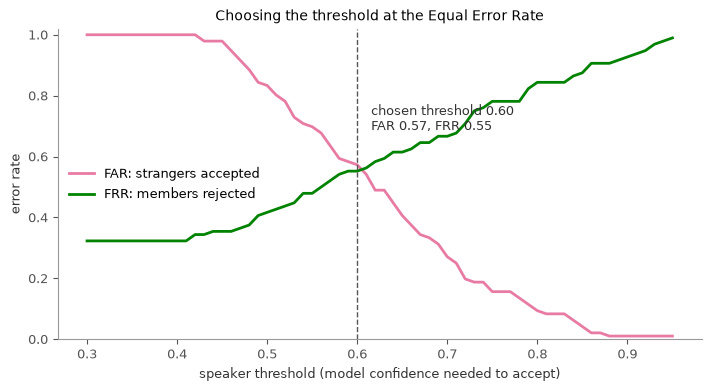

,left_out,clips,highest_probability
0,agnes,36,0.834
1,aime,12,0.964
2,naillah,36,0.876
3,sheja,12,0.781


In [10]:
impostors = vm.impostor_test(features)
genuine = vm.genuine_scores(held_out)
impostor = np.concatenate(impostors["probabilities"].to_list())
threshold, far, frr = vm.choose_threshold(genuine, impostor)
table = vm.error_rate_table(genuine, impostor)

fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
# Not member colours: these lines are error rates, not people
ax.plot(table["threshold"], table["FAR"], color="#e87ba4", lw=2, label="FAR: strangers accepted")
ax.plot(table["threshold"], table["FRR"], color="#008300", lw=2, label="FRR: members rejected")
ax.axvline(threshold, color="#555", lw=1, ls="--")
ax.annotate(f"chosen threshold {threshold:.2f}\nFAR {far:.2f}, FRR {frr:.2f}", (threshold, max(far, frr)),
            xytext=(10, 25), textcoords="offset points", fontsize=9, color="#333")
ax.set(xlabel="speaker threshold (model confidence needed to accept)", ylabel="error rate", ylim=(0, 1.02),
       title="Choosing the threshold at the Equal Error Rate")
ax.legend(frameon=False, loc="center left")
save(fig, "audio_06_far_frr.png")
plt.show()
display(impostors.drop(columns=["probabilities", "phrase_probabilities"]))

## 7. Final model, unauthorized voice and `verify_voice`

The final model is trained on every row with the chosen threshold and saved to `models/voice_model.joblib`.
The app calls `verify_voice(audio_path)`, which accepts WAV or phone `.m4a` files and returns the member's name or `"unauthorized"`. The app then checks that this is the **same member** the face model identified.

The unauthorized clips (a speaker outside the team, saying both approved phrases) are never used for training. Below, they and their augmentations go through the final model.

In [11]:
import joblib
model = vm.fit(features, speaker_threshold=threshold)
vm.MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, vm.MODEL_FILE)
print(f"Saved {vm.MODEL_FILE.relative_to(ROOT)} with speaker threshold {threshold:.2f}")
unauthorized = vm.unauthorized_test(model)
display(unauthorized)
print(f"Unauthorized clips rejected: {(unauthorized['result'] == vm.UNAUTHORIZED).sum()} of {len(unauthorized)}")

Saved models/voice_model.joblib with speaker threshold 0.60


/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/aggie/Desktop/formative 2/formative2-multimodal-auth/.venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


,clip,augmentation,result,closest_member,probability,phrase,phrase_probability
0,unauthorized_confirmtransaction.wav,original,unauthorized,agnes,0.405,yesapprove,0.688
1,unauthorized_confirmtransaction.wav,pitch_up,unauthorized,agnes,0.358,yesapprove,0.631
2,unauthorized_confirmtransaction.wav,pitch_down,unauthorized,agnes,0.534,yesapprove,0.641
3,unauthorized_confirmtransaction.wav,faster,unauthorized,agnes,0.530,yesapprove,0.657
4,unauthorized_confirmtransaction.wav,slower,unauthorized,agnes,0.473,yesapprove,0.696
5,unauthorized_confirmtransaction.wav,noisy,unauthorized,agnes,0.344,yesapprove,0.673
6,unauthorized_yesapprove.wav,original,unauthorized,aime,0.433,yesapprove,0.961
7,unauthorized_yesapprove.wav,pitch_up,unauthorized,aime,0.393,yesapprove,0.961
8,unauthorized_yesapprove.wav,pitch_down,unauthorized,agnes,0.421,yesapprove,0.798
9,unauthorized_yesapprove.wav,faster,unauthorized,agnes,0.371,yesapprove,0.957


Unauthorized clips rejected: 12 of 12


In [12]:
vm._load.cache_clear()   # make verify_voice load the model just saved
demo = [ap.PROCESSED / f"{m}_confirmtransaction.wav" for m in members] + sorted(ap.RAW.glob("unauthorized*"))
pd.DataFrame([{"file": p.name, "verify_voice": vm.verify_voice(p), "reason": vm.voice_details(p)["reason"]} for p in demo])

,file,verify_voice,reason
0,agnes_confirmtransaction.wav,agnes,matches an enrolled member saying an approved ...
1,aime_confirmtransaction.wav,aime,matches an enrolled member saying an approved ...
2,naillah_confirmtransaction.wav,naillah,matches an enrolled member saying an approved ...
3,sheja_confirmtransaction.wav,sheja,matches an enrolled member saying an approved ...
4,unauthorized_confirmtransaction.m4a,unauthorized,closest member agnes is only 0.40 likely (need...
5,unauthorized_yesapprove.m4a,unauthorized,closest member aime is only 0.43 likely (needs...


(The member clips above were part of training, so this cell checks the function the app calls, not accuracy. Accuracy is in sections 5 and 6.)

## 8. Summary and limitations

* **Pipeline:** convert, trim, normalise, check (names, length, clipping, exact copies), 5 measured augmentations, and 34 window features in `features/audio_features.csv`.
* **Model:** speaker and phrase Logistic Regression with grouped cross-validation. Accuracy, F1 and log loss are in section 5, and FAR and FRR at an automatically chosen threshold in section 6.
* **Main limitation: the amount of data.** Each member has between 2 and 6 recordings. Results improved sharply as members added real takes, while copies of existing takes changed nothing (and inflated scores to 100% when not caught). More takes per member, recorded in different places, is the clearest next step.
* **Recording conditions leak into the model.** Sheja's room hum makes her easier to recognise for the wrong reason. Recording everyone in similar conditions, or training on more varied conditions, would reduce this.
* **The phrase check is weak.** It distinguishes the two approved phrases from each other, but it has never seen a *wrong* phrase, so it cannot reliably reject one. A real system would use speech recognition for this.
* **Noise is the biggest risk at login:** even 30 dB of noise moved voiceprints further than the gap between two members.